# Reconstruction and calibration

Generates a phantom with a known center-of-rotation deviation, normalizes it, and reconstructs through the `algotom_fbp` backend: a single slice with the wrong (nominal) center versus the correct one, then a stack of several slices, then calibration finding the center and tilt automatically.

In [1]:
import sys
from pathlib import Path

here = Path.cwd()
project_root = next(p for p in [here, *here.parents] if (p / "data_import").is_dir())
sys.path.insert(0, str(project_root))

print("Using project root:", project_root)

Using project root: d:\GitHub\Universial-Reconstructions


## 1. Generate a phantom

A center-of-rotation deviation of 8px, no tilt, no detector defects.

In [2]:
from tests.fixtures.realistic_phantom import generate, to_project_object

TRUE_COR = 8.0  # pixels

phantom = generate(
    shape=(12, 96, 96), n_angles=300,
    cor_deviation=TRUE_COR, tilt_deg=0.0,
    n_scratches=0, n_defective_pixels=0, inhomogeneity_strength=0.0,
    noise_level=0.0, seed=1,
)
print("volume shape:", phantom.volume.shape)
print("true_center_of_rotation:", phantom.true_center_of_rotation, "px")

volume shape: (12, 96, 96)
true_center_of_rotation: 8.0 px


## 2. Project object and normalization

In [3]:
from preprocessing import build_reference, normalize_rows

project = to_project_object(phantom)
reference = build_reference(project)
normalized = normalize_rows(project, slice(None), reference)

print(project)
print("normalized shape:", normalized.shape)

ProjectObject(format=hdf5, storage_mode=ram, vendor=generic_parallel_synchrotron_hdf5, handles=['projections', 'flats', 'darks'])
normalized shape: (300, 12, 96)


## 3. Reconstruct one slice: wrong center vs. correct center

`reconstruct()` takes a single 2D sinogram and returns a single 2D image.

In [4]:
from reconstruction import Geometry, reconstruct

row = phantom.volume.shape[0] // 2
sinogram = normalized[:, row, :]
width = sinogram.shape[1]
geometry = Geometry(geometry_type="parallel")

nominal_center = width / 2
correct_center = width / 2 + TRUE_COR

image_wrong = reconstruct(sinogram, phantom.angles, center=nominal_center, geometry=geometry, backend="algotom_fbp")
image_right = reconstruct(sinogram, phantom.angles, center=correct_center, geometry=geometry, backend="algotom_fbp")

print("image_wrong shape:", image_wrong.shape)
print("image_right shape:", image_right.shape)

image_wrong shape: (96, 96)
image_right shape: (96, 96)


d:\GitHub\Universial-Reconstructions\.venv\Lib\site-packages\algotom\rec\reconstruction.py:422: UserWarning: !!!No Nvidia GPU found! Run with CPU instead!!!
  warnings.warn("!!!No Nvidia GPU found! Run with CPU instead!!!")


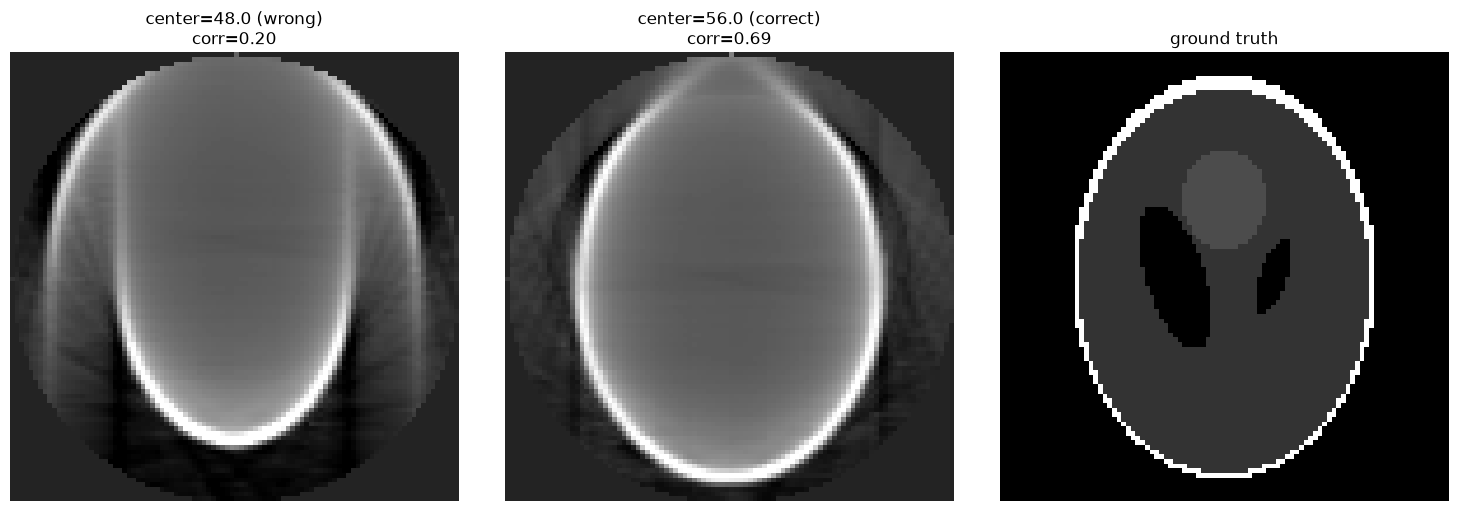

In [5]:
import numpy as np
import matplotlib.pyplot as plt


def corr(a, b):
    return np.corrcoef(a.ravel(), b.ravel())[0, 1]


ground_truth = phantom.volume[row]

vmin, vmax = np.percentile(np.concatenate([image_wrong.ravel(), image_right.ravel()]), [1, 99])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image_wrong, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title(f"center={nominal_center} (wrong)\ncorr={corr(image_wrong, ground_truth):.2f}")
axes[1].imshow(image_right, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title(f"center={correct_center} (correct)\ncorr={corr(image_right, ground_truth):.2f}")
axes[2].imshow(ground_truth, cmap="gray")
axes[2].set_title("ground truth")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The wrong-center reconstruction is off-axis and asymmetrically cropped, with a visible seam artifact. Neither panel matches the ground truth exactly; that residual gap is FBP/Gibbs-ringing behavior for this phantom, present even with a correct center (see `tests/test_reconstruction.py`).

## 4. Units: "per pixel" vs. real attenuation coefficients

With no `detector_pixel_size` set on `geometry`, `image_right`'s values are attenuation coefficients in "per pixel" units. Setting `detector_pixel_size` on `Geometry` (micrometers) makes `reconstruct()` divide its output by that value, returning attenuation in inverse micrometers (1/um). See [`RECONSTRUCTION.md`](../RECONSTRUCTION.md)'s "Units" section.

In [6]:
detector_pixel_size_um = 2.5  # a plausible detector pixel pitch
geometry_um = Geometry(geometry_type="parallel", detector_pixel_size=detector_pixel_size_um)

image_right_um = reconstruct(sinogram, phantom.angles, center=correct_center, geometry=geometry_um, backend="algotom_fbp")

print("peak value, per-pixel units (no detector_pixel_size):", image_right.max(), "1/px")
print("peak value, real attenuation units (detector_pixel_size=2.5um):", image_right_um.max(), "1/um")
print("ratio:", image_right.max() / image_right_um.max(), "(close to but not exactly", detector_pixel_size_um, "-- see below)")
print("dtype:", image_right_um.dtype)

peak value, per-pixel units (no detector_pixel_size): 0.85243535 1/px
peak value, real attenuation units (detector_pixel_size=2.5um): 0.36543524 1/um
ratio: 2.3326578 (close to but not exactly 2.5 -- see below)
dtype: float32


d:\GitHub\Universial-Reconstructions\.venv\Lib\site-packages\algotom\rec\reconstruction.py:422: UserWarning: !!!No Nvidia GPU found! Run with CPU instead!!!
  warnings.warn("!!!No Nvidia GPU found! Run with CPU instead!!!")


The ratio above is close to, not exactly, `detector_pixel_size_um`: this cell reconstructs the sinogram a second time, and algotom's FBP is not perfectly bit-reproducible between separate calls on its CPU fallback path. The unit conversion itself is an exact division, checked in `tests/test_reconstruction.py` against a deterministic backend.

## 5. Reconstruct several slices at once

Passing a 3D stack instead of a single 2D sinogram returns a matching 3D stack of images; `reconstruct()` is a single function for both cases.

`normalized` is `(n_angles, height, width)`, angle-first. Slicing several rows with `normalized[:, rows, :]` keeps that convention, `(n_angles, len(rows), width)`, which is the shape `reconstruct()` expects for a stack.

In [7]:
rows = [4, 5, 6, 7, 8]  # inside the phantom's height extent
sinogram_stack = normalized[:, rows, :]

images = reconstruct(sinogram_stack, phantom.angles, center=correct_center, geometry=geometry, backend="algotom_fbp")
print("input stack shape:", sinogram_stack.shape)
print("output stack shape:", images.shape)  # (n_slices, height, width)

input stack shape: (300, 5, 96)
output stack shape: (5, 96, 96)


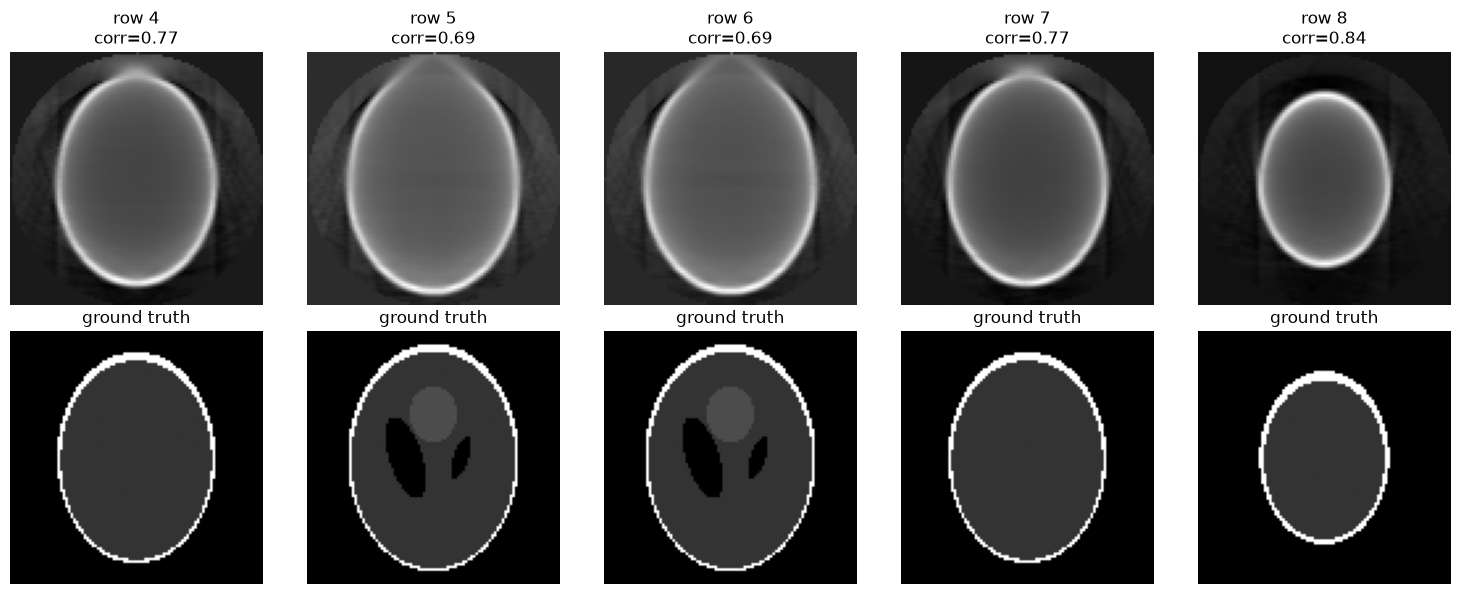

In [8]:
fig, axes = plt.subplots(2, len(rows), figsize=(3 * len(rows), 6))
for col, r in enumerate(rows):
    axes[0, col].imshow(images[col], cmap="gray")
    axes[0, col].set_title(f"row {r}\ncorr={corr(images[col], phantom.volume[r]):.2f}")
    axes[1, col].imshow(phantom.volume[r], cmap="gray")
    axes[1, col].set_title("ground truth")
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

Every slice lands in roughly the same correlation range. The phantom's cross-section changes shape row to row; reconstruction tracks that correctly at every height.

## 6. Calibration: finding the center of rotation automatically

`correct_center` above was set from the known `TRUE_COR`. `calibration.find_center()` finds it directly from the sinogram, without being given `TRUE_COR`:

In [9]:
from calibration import find_center

found_center = find_center(sinogram, backend="algotom")

print("find_center() result:            ", found_center)
print("hand-set correct_center used above:", correct_center)
print("true center (never given to find_center):", width / 2 + TRUE_COR)

find_center() result:             55.5
hand-set correct_center used above: 56.0
true center (never given to find_center): 56.0


`find_center()` is deterministic sinogram-domain math; it does not reconstruct anything, and calling it twice on the same sinogram gives the same answer.

## 7. Calibration: finding rotation-axis tilt

A separate phantom, generated with a rotation-axis tilt (axis lean: the rotation axis not parallel to the detector's rows, so the effective center drifts linearly with row height). This needs more rows than the phantom above, so `find_tilt()` has enough samples to fit a line.

`calibration` splits center-finding and tilt-finding into two functions: `find_center()` on one row, `find_tilt()` across several. A manually determined center can pair with an automatically found tilt, or vice versa.

In [10]:
TRUE_TILT_COR = 4.0    # pixels, at the middle row
TRUE_TILT_DEG = 10.0   # degrees of axis lean

tilt_phantom = generate(
    shape=(24, 96, 96), n_angles=300,
    cor_deviation=TRUE_TILT_COR, tilt_deg=TRUE_TILT_DEG,
    n_scratches=0, n_defective_pixels=0, inhomogeneity_strength=0.0,
    noise_level=0.0, seed=11,
)
tilt_project = to_project_object(tilt_phantom)
tilt_reference = build_reference(tilt_project)
tilt_normalized = normalize_rows(tilt_project, slice(None), tilt_reference)
n_tilt_rows = tilt_normalized.shape[1]
tilt_middle_row = (n_tilt_rows - 1) // 2

print("normalized shape:", tilt_normalized.shape)

normalized shape: (300, 24, 96)


`find_tilt()`: sample several rows spread across the stack, skipping a margin at the top and bottom; call `find_center()` independently on each row's sinogram; drop any row whose estimate is far from the median of the others; fit a line (center vs. row index) through what's left; the slope gives the tilt angle. `num_rows`/`margin`/`outlier_tolerance` here match the values used in `tests/test_calibration.py`'s end-to-end check against this phantom shape.

In [11]:
from calibration import find_center, find_tilt, centers_for_rows

tilt_result = find_tilt(tilt_normalized, backend="algotom", num_rows=14, margin=4, outlier_tolerance=6.0)
center_at_middle = find_center(tilt_normalized[:, tilt_middle_row, :], backend="algotom")

print("recovered tilt_deg:", tilt_result.tilt_deg, " true:", TRUE_TILT_DEG)
print("find_center() at middle row:      ", center_at_middle)
print("find_tilt()'s own cross-check there:", tilt_result.center_at_reference_row, "(should roughly agree)")
print("true center at middle row:", width / 2 + TRUE_TILT_COR)
print("rows sampled:  ", tilt_result.rows)
print("per-row centers:", np.round(tilt_result.centers, 2))
print("used (not an outlier):", tilt_result.used)

recovered tilt_deg: 10.298435427702364  true: 10.0
find_center() at middle row:       51.25
find_tilt()'s own cross-check there: 51.48858682489709 (should roughly agree)
true center at middle row: 52.0
rows sampled:   [ 4  5  6  7  8  9 10 12 13 14 15 16 17 19]
per-row centers: [50.   50.   50.75 50.75 51.   51.   51.25 51.75 51.75 52.   52.   52.25
 52.25 53.  ]
used (not an outlier): [ True  True  True  True  True  True  True  True  True  True  True  True
  True  True]


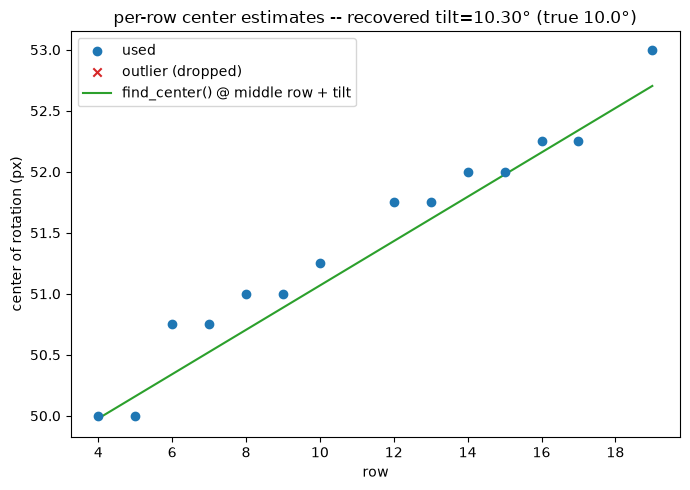

In [12]:
fit_rows = np.array([tilt_result.rows.min(), tilt_result.rows.max()])
fit_centers = centers_for_rows(tilt_result.tilt_deg, center_at_middle, reference_row=tilt_middle_row, rows=fit_rows)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(tilt_result.rows[tilt_result.used], tilt_result.centers[tilt_result.used], label="used", zorder=3)
ax.scatter(tilt_result.rows[~tilt_result.used], tilt_result.centers[~tilt_result.used], label="outlier (dropped)", marker="x", color="tab:red", zorder=3)
ax.plot(fit_rows, fit_centers, color="tab:green", label="find_center() @ middle row + tilt")
ax.set_xlabel("row")
ax.set_ylabel("center of rotation (px)")
ax.set_title(f"per-row center estimates -- recovered tilt={tilt_result.tilt_deg:.2f}° (true {TRUE_TILT_DEG}°)")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Applying the correction: `centers_for_rows()`

Axis lean is a different center per row, and `reconstruct()` accepts one center per slice. `calibration.centers_for_rows()` takes a `tilt_deg`, `center`, and `reference_row` and produces that array. Reconstructing the same rows with a single constant center (ignoring the tilt) versus this per-row array shows the effect, on the row farthest from the middle:

In [13]:
tilt_rows = [6, 9, 12, 15, 18]
tilt_stack = tilt_normalized[:, tilt_rows, :]

per_row_centers = centers_for_rows(tilt_result.tilt_deg, center_at_middle, reference_row=tilt_middle_row, rows=tilt_rows)

images_uncorrected = reconstruct(tilt_stack, tilt_phantom.angles, center=center_at_middle, geometry=geometry, backend="algotom_fbp")
images_corrected = reconstruct(tilt_stack, tilt_phantom.angles, center=per_row_centers, geometry=geometry, backend="algotom_fbp")

print(f"{'row':>4}  {'uncorrected corr':>17}  {'corrected corr':>15}")
for i, r in enumerate(tilt_rows):
    c_un = corr(images_uncorrected[i], tilt_phantom.volume[r])
    c_co = corr(images_corrected[i], tilt_phantom.volume[r])
    print(f"{r:>4}  {c_un:>17.3f}  {c_co:>15.3f}")

 row   uncorrected corr   corrected corr
   6              0.814            0.848
   9              0.808            0.792
  12              0.753            0.771
  15              0.702            0.806
  18              0.693            0.866


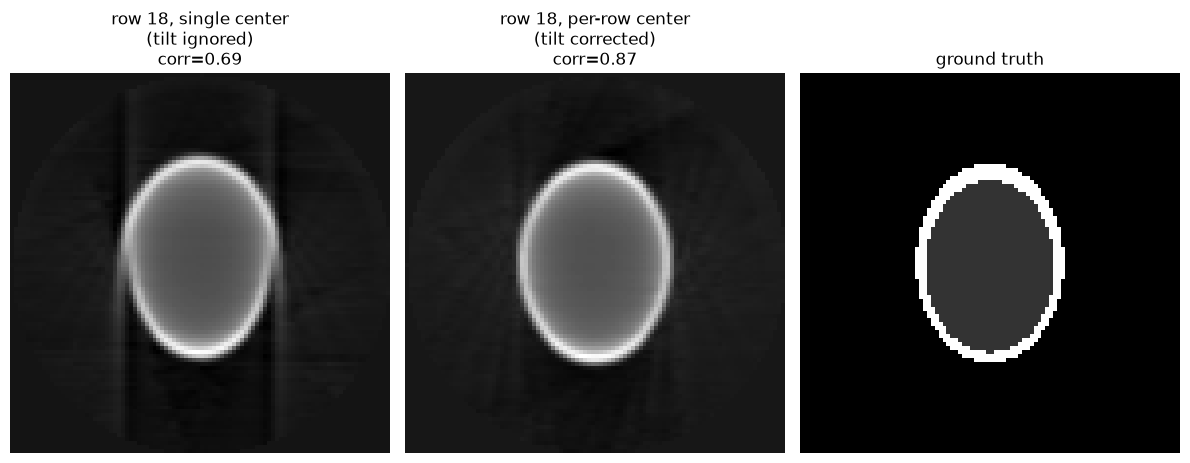

In [14]:
farthest = int(np.argmax(np.abs(np.array(tilt_rows) - tilt_middle_row)))
r = tilt_rows[farthest]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
axes[0].imshow(images_uncorrected[farthest], cmap="gray")
axes[0].set_title(f"row {r}, single center\n(tilt ignored)\ncorr={corr(images_uncorrected[farthest], tilt_phantom.volume[r]):.2f}")
axes[1].imshow(images_corrected[farthest], cmap="gray")
axes[1].set_title(f"row {r}, per-row center\n(tilt corrected)\ncorr={corr(images_corrected[farthest], tilt_phantom.volume[r]):.2f}")
axes[2].imshow(tilt_phantom.volume[r], cmap="gray")
axes[2].set_title("ground truth")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. `find_tilt(center=...)`

`find_tilt()` accepts an optional `center`: an already-known center of rotation that re-centers each sampled row's search window on it. This matters when an uncorrected offset is large relative to the detector width; at a proportion typical of a real detector (this phantom's `TRUE_TILT_COR = 4.0` on a 96-column width), it has no measurable effect:

In [15]:
tilt_result_with_hint = find_tilt(
    tilt_normalized, backend="algotom", center=center_at_middle,
    num_rows=14, margin=4, outlier_tolerance=6.0,
)

print("tilt_deg without center hint:", tilt_result.tilt_deg)
print("tilt_deg with center hint:   ", tilt_result_with_hint.tilt_deg)

tilt_deg without center hint: 10.298435427702364
tilt_deg with center hint:    10.298435427702364


They match. `center` earns its keep only at a severe misalignment, well beyond what a real detector's offset-to-width ratio would produce; see [`CALIBRATION.md`](../CALIBRATION.md)'s `find_tilt()` section.

## Recap

```
generate() -> PhantomProject -> to_project_object() -> ProjectObject
                                        |
                          build_reference() + normalize_rows() -> normalized sinograms
                                        |
        calibration.find_center() (one row)  +  calibration.find_tilt() (several rows,
                                                  optionally pre-corrected with center=)
                                        |
                      calibration.centers_for_rows(tilt_deg, center, reference_row, rows)
                                        |
                     reconstruct(sinogram_or_stack, angles, centers, geometry, backend="algotom_fbp")
                                        |
                     float32 attenuation coefficients, 1/um if geometry.detector_pixel_size
                     is set, otherwise "per pixel"
```

See [`CALIBRATION.md`](../CALIBRATION.md) and [`RECONSTRUCTION.md`](../RECONSTRUCTION.md) for the full reference, and `tests/test_calibration.py`/`tests/test_reconstruction.py` for test coverage.